PROJECT 2 - PREDICTING WAVE HEIGHT 

This is a dataset captured from a buoy north of Kauai that Hawaiians use to determine wave quality and height in the North Shore communities. I want to train this model using Linear Regression and Random Forest to predict wave height, based on other features like wind speed, wind gust speed, dominant wave period, etc. I feel that the two models I have selected will clearly show the difference in why one is better than the other for this problem. 

This dataset is used by surf forecast companies, and locals in Hawaii to gauge when the surf will be firing. 

https://www.ndbc.noaa.gov/station_page.php?station=51001

In [30]:
#import necessary packages

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit, cross_val_score


Preparing the DataFrame

In [ ]:
#Read the data into a df

df2024 = pd.read_csv("51001h2024.txt", sep=r"\s+", header=0, skiprows=[1])
df2025 = pd.read_csv("51001h2025.txt", sep=r"\s+", header=0, skiprows=[1])

df = pd.concat([df2024, df2025], ignore_index=True)

#Consolidating all the date rows into one row 'datetime' and dropping after for simplicity
df["datetime"] = pd.to_datetime(df[["#YY", "MM", "DD", "hh", "mm"]].rename(columns={"#YY": "year", "MM": "month", "DD": "day", "hh": "hour", "mm": "minute"}))

df = df.drop(columns=["#YY", "MM", "DD", "hh", "mm", "VIS", "TIDE"])

#Changing null values to NaN
na_codes = {
    "WDIR": 999, "WSPD": 99, "GST": 99, "WVHT": 99,
    "DPD": 99, "APD": 99, "MWD": 999, "PRES": 9999,
    "ATMP": 9999, "WTMP": 999, "DEWP": 999,
}

df = df.replace(na_codes, np.nan)

#Dropping rows that don't have all of the following features
df = df.dropna(subset=["WVHT", "WSPD", "GST", "PRES"])


df.head()

WDIR = wind direction in degrees (0 = north) \
WSPD = wind speed \
GST = wind gust speed \
WVHT = significant wave height (the target) \
DPD = dominant wave period or time between biggest waves \
APD = average wave period \
MWD = mean wave direction (where waves are coming from) \
PRES = air pressure at sea level \
ATMP = air temperature \
WTMP = water temperature \
DEWP = dew point

Dropping all rows that are NaN for certain features results in 34,000 records left in the dataframe. Plenty to work with still. 

In [ ]:
df.shape

(34400, 12)

In [ ]:
df.describe().round(2)

,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,datetime
count,34386.00,34400.00,34400.00,34400.00,34400.00,34400.00,34400.00,34400.00,34400.00,34224.00,34365.00,34400
mean,112.32,6.47,8.26,2.28,10.77,7.04,180.19,1017.83,24.71,25.52,20.96,2024-12-31 12:21:07.360465
min,1.00,0.00,0.40,0.74,4.17,4.55,0.00,999.40,17.20,22.30,9.60,2024-01-01 00:10:00
25%,71.00,4.90,6.40,1.69,8.33,6.04,86.00,1016.00,23.40,24.20,19.90,2024-07-01 08:02:30
50%,88.00,6.70,8.40,2.08,10.00,6.70,116.00,1018.20,25.00,25.70,21.70,2024-12-31 15:55:00
75%,123.00,8.10,10.10,2.66,12.90,7.73,311.00,1020.10,26.10,27.00,22.60,2025-07-02 12:17:30
max,360.00,17.10,22.90,8.93,23.53,14.32,359.00,1028.40,999.00,29.90,25.60,2025-12-31 23:40:00
std,72.43,2.30,2.75,0.84,2.87,1.35,117.99,3.66,7.65,1.53,2.50,NaN


In [ ]:
#Row for maximum wave height in meters
maxwvht = df.loc[df["WVHT"].idxmax()]
print(maxwvht)

WDIR                      331.0
WSPD                        8.5
GST                        12.7
WVHT                       8.93
DPD                       17.39
APD                       12.95
MWD                       306.0
PRES                     1017.7
ATMP                       19.7
WTMP                       23.0
DEWP                       12.4
datetime    2024-02-15 22:10:00
Name: 6613, dtype: object


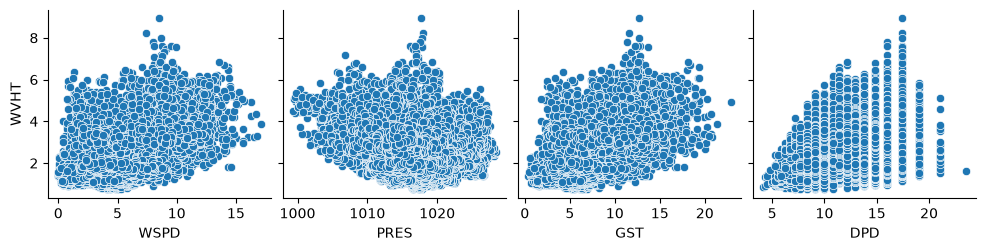

In [ ]:
#sns.scatterplot(data=df, x="WSPD", y="WVHT")
sns.pairplot(df, x_vars=['WSPD', 'PRES', 'GST', 'DPD'], y_vars=['WVHT'])

Most of the points are clustered in the middle, but for all of the graphs, max wave height seems to happen towards the middle of the axis. Interesting.

Linear Regression: 
Wind speed, Wind gust speed, pressure, and dominant wave period are the features. \
Wave height is the target. 

In [ ]:
X = df[["WSPD", "GST", "PRES", "DPD"]]
y = df["WVHT"]

#Shuffle = False to train on 2024 and test on 2025. 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, shuffle=False)

In [ ]:
#Declare linear regression model and train / predict
linmodel = LinearRegression()
linmodel.fit(X_train, y_train)

y_pred_lin = linmodel.predict(X_test)

In [ ]:
#Calculating error and scores, and describing y_test for comparison
MSE = mean_squared_error(y_test, y_pred_lin)
RMSE = np.sqrt(MSE)
R2 = r2_score(y_test, y_pred_lin)
actual = y_test.describe()
MSETR = mean_squared_error(y_train, linmodel.predict(X_train))
RMSETR = np.sqrt(MSETR)
R2TR = r2_score(y_train, linmodel.predict(X_train))

In [ ]:
print(actual)
print(f"MSE: {MSE}")
print(f"RMSE: {RMSE}")
print(f"R2 Score: {R2}")
print(f"Training MSE: {MSETR}")
print(f"Training RMSE: {RMSETR}")
print(f"Training R2 Score: {R2TR}")

count    8600.000000
mean        2.087445
std         0.716751
min         0.740000
25%         1.580000
50%         1.950000
75%         2.430000
max         5.730000
Name: WVHT, dtype: float64
MSE: 0.3121093968937765
RMSE: 0.5586675190968028
R2 Score: 0.39239652926914825
Training MSE: 0.38054618216277947
Training RMSE: 0.616884253456659
Training R2 Score: 0.48771714407752387


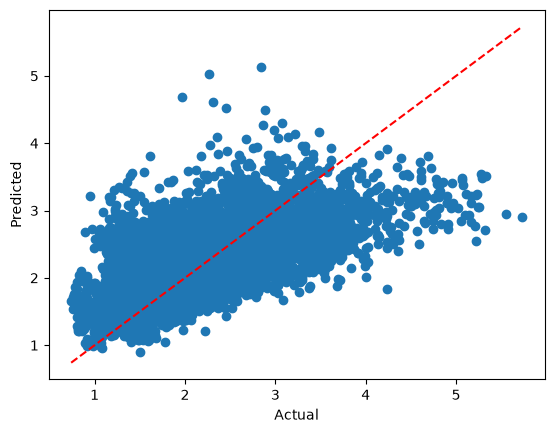

In [ ]:
plt.scatter(y_test, y_pred_lin)
lims = [min(y_test.min(), y_pred_lin.min()), max(y_test.max(), y_pred_lin.max())]
plt.plot(lims, lims, linestyle="--", color="red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

The results of the Linear Regression model aren't great, but aren't terrible. Given the RMSE is less than the std tells us that the model is doing more than just guessing the mean. The RMSE shows that a prediction from this model is typically off by 0.56 meters, or about 1.83 feet on waves that average 2 meters or 6.5 feet. 

Random Forest:

Now we see how a Random Forest model compares to the Linear Regression model's RMSE of 0.56. 

In [ ]:
n_values = [10, 30, 50, 75, 100, 200, 300, 400, 600, 900]

rmse_scores = []

for n in n_values:
    rfmodel = RandomForestRegressor(n_estimators=n, min_samples_leaf=1, random_state=42)
    rfmodel.fit(X_train, y_train)

    y_pred_rf = rfmodel.predict(X_test)

    MSE2 = mean_squared_error(y_test, y_pred_rf)
    RMSE2 = np.sqrt(MSE2)

    rmse_scores.append(RMSE2)


<Axes: >

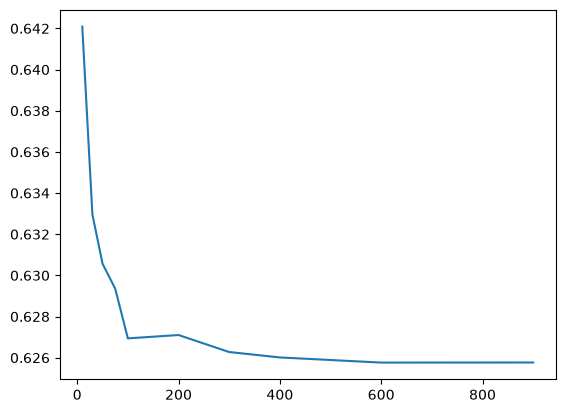

In [ ]:
sns.lineplot(x=n_values, y=rmse_scores)

We see that the RMSE starts to plateau around 600 estimators.

We will use 600 estimators to compute the error and scores to then compare to the Linear Regression model. Based on the graph, the RMSE looks like it isn't as good. 

In [ ]:
rf2model = RandomForestRegressor(criterion = 'squared_error', n_estimators=100, min_samples_leaf=20, random_state=42)
rf2model.fit(X_train, y_train)

rf2predict = rf2model.predict(X_test)

MSE3 = mean_squared_error(y_test, rf2predict)
RMSE3 = np.sqrt(MSE3)
R2Score = r2_score(y_test, rf2predict)

MSETR = mean_squared_error(y_train, rf2model.predict(X_train))
RMSETR = np.sqrt(MSETR)
R2TR = r2_score(y_train, rf2model.predict(X_train))


In [ ]:
print(f"MSE = {MSE3}")
print(f"RMSE = {RMSE3}")
print(f"R2 Score = {R2Score}")
print(f"Training MSE = {MSETR}")
print(f"Training RMSE = {RMSETR}")
print(f"Training R2 Score = {R2TR}")

MSE = 0.38853678581633627
RMSE = 0.6233271900184816
R2 Score = 0.24361040738237738
Training MSE = 0.2516419573587897
Training RMSE = 0.5016392701521579
Training R2 Score = 0.6612451612231904


The RMSE of the Random Forest model tells us that it is off by an average of .63 meters or 2.07 feet for a wave that average 2 meters or 6.5 feet. 

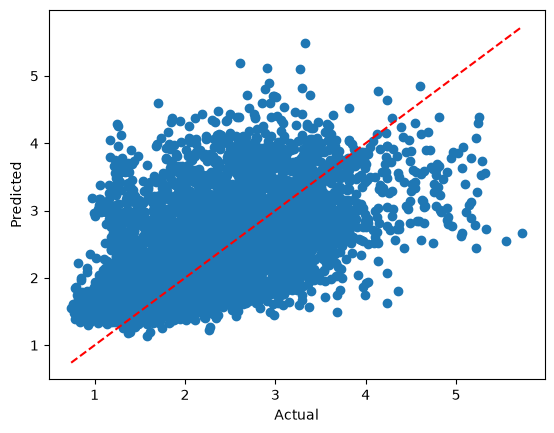

In [ ]:
plt.scatter(y_test, rf2predict)
lims = [min(y_test.min(), rf2predict.min()), max(y_test.max(), rf2predict.max())]
plt.plot(lims, lims, linestyle="--", color="red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

Based on those results above, the Linear Regression model is more accurate.

Scores: 

Random Forest: RMSE=0.62, R2 Score=0.24, difference of 2.07 feet\
Linear Regression: RMSE=0.56, R2 Score = 0.39, difference of 1.83 feet

CONCLUSION:

First glance of these two models, I was hoping that the Random Forest performed a little better. But it was not better than the Linear Regression model, as expected. Training on 2024 data and testing on 2025 data I think is largely responsible. The 2025 data was all within the max/min values of the 2024 data. 

What both models showed us are the limitations of this data. I think the R2 Scores could be a lot better. Yes it is used by other companies to predict surf conditions, but they also use more than just this dataset. This buoy is about 188 nautical miles of Kauai, so more data is needed to predict swells closer to shore. Beyond the scope of this project I want to explore what other datasets could be beneficial in optimizing the Linear Regression model even further. If we could get a predicted difference of closer to 1.5 feet, and higher R2 scores (maybe around 6 or 7), I would be satisfied. A lot of surf companies give a range of +/- 2 feet in their forecasts. With that in mind, getting down to an RMSE of .56 meters, or 1.83 feet isn't bad at all. 

In [ ]:
param_grid = {"min_samples_leaf": [1, 5, 10, 20, 50], "n_estimators": [100, 200, 400, 600, 800]}

tscv = TimeSeriesSplit(n_splits=5)

search = GridSearchCV(rf2model, param_grid, cv=tscv, scoring="neg_mean_squared_error")
search.fit(X,y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'min_samples_leaf': [1, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verb